# 接触对象：伙伴数分布

接触对象为其他浓相链；零伙伴保留，无选中链的帧缺失。参数以保存结果为准。

在首个代码单元选择OBJECT：central_chain为每帧中心链，dense_chains为全部浓相链。


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project among the working directory and its parents.
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "simulations.yaml").is_file()), None
)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the project, or set ROOT explicitly")
sys.path.insert(0, str(ROOT))
from common import inputs
from common import results as files

CONFIG = ROOT / "simulations.yaml"
SELECTED = None  # None means all registered simulations.
OBJECT = "central_chain"  # central_chain / dense_chains
RESULTS_ROOT = ROOT / "03_results"
SIMULATIONS = inputs.select_simulations(CONFIG, SELECTED)
RESULTS = {s["id"]: files.completed(RESULTS_ROOT / s["id"] / "02_contacts/02_inter" / OBJECT) for s in SIMULATIONS}
SOURCES = {key: files.read_json(path / "metadata.json") for key, path in RESULTS.items()}
COLORS = {name: plt.get_cmap("tab10")(i % 10) for i, name in enumerate(RESULTS)}
FIGURES = ROOT / "05_plot/02_contacts/02_inter/figures" / OBJECT
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "font.size": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    }
)


def export(fig, name):
    for key, path in RESULTS.items():
        files.completed(path)
        if files.read_json(path / "metadata.json") != SOURCES[key]:
            raise ValueError("Results changed; restart and rerun the notebook")
    for extension in ("png", "pdf", "svg"):
        fig.savefig(FIGURES / f"{name}.{extension}", dpi=300, bbox_inches="tight")
    files.write_json(
        FIGURES / f"{name}.sources.json",
        {key: files.read_json(path / "metadata.json") for key, path in RESULTS.items()},
    )


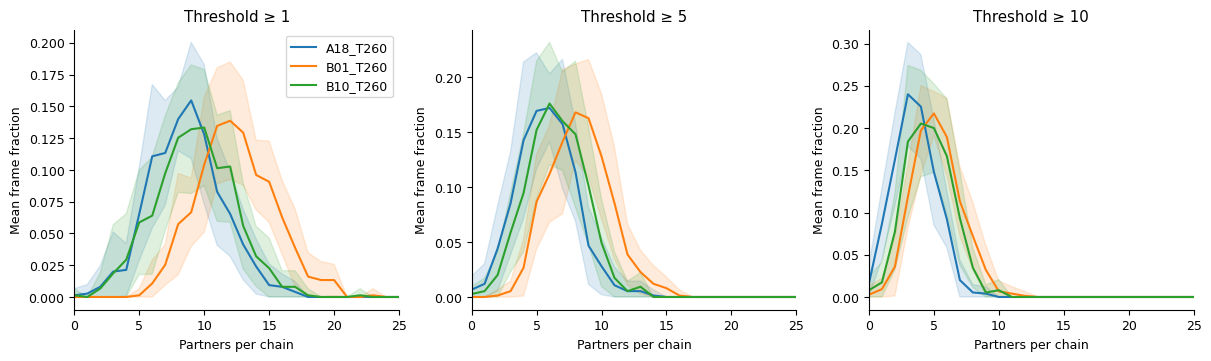

In [2]:
THRESHOLDS = sorted(
    set.intersection(*(set(meta["parameters"]["partner_thresholds"]) for meta in SOURCES.values()))
)
if not THRESHOLDS:
    raise ValueError("No shared thresholds among selected results")

fig, axes = plt.subplots(
    1, len(THRESHOLDS), figsize=(4 * len(THRESHOLDS), 3.5), squeeze=False, constrained_layout=True
)
for threshold, ax in zip(THRESHOLDS, axes[0]):
    for name, path in RESULTS.items():
        mean = pd.read_csv(path / "partner_distribution.csv")
        block = pd.read_csv(path / "partner_distribution_blocks.csv")
        data = mean[mean.threshold.eq(threshold)].sort_values("partner_count")
        spread = block[block.threshold.eq(threshold)].groupby("partner_count").fraction.std()
        sd = spread.reindex(data.partner_count).to_numpy()
        x, y = data.partner_count.to_numpy(), data["mean"].to_numpy()
        ax.plot(x, y, label=name, color=COLORS[name])
        ax.fill_between(
            x, np.maximum(0, y - sd), np.minimum(1, y + sd), color=COLORS[name], alpha=0.15
        )
    ax.set(
        xlim=(0, 25),
        xticks=np.arange(0, 26, 5),
        xlabel="Partners per chain",
        ylabel="Mean frame fraction",
        title=f"Threshold ≥ {threshold}",
    )
axes[0, 0].legend()
export(fig, "partner_distribution")
plt.show()
